# A synthetic process from identification to validation

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/fobos123deimos/Undergraduate-Course-Control-of-Dynamical-Systems/blob/main/laboratories/12-identification-capstone/notebook.ipynb)

## Goal
Create a reproducible synthetic identification experiment with gain $K=1.8$, time constant $\tau=4\,\mathrm{s}$ and delay $\theta=0.6\,\mathrm{s}$. Apply a two-unit step at $t=2\,\mathrm{s}$, sample every $0.05\,\mathrm{s}$ and add independent Gaussian noise with standard deviation $0.015$ using seed 2026. Estimate the parameters without initializing at truth, validate on a separate multistep record, and tune PI using $\lambda=2\,\mathrm{s}$. Assess the delayed closed loop with $u\in[0,2]$, distinguishing training, validation and simulated controller evaluation.

**Evidence:** every parameter and dataset is synthetic and was chosen for this original teaching scenario.

## Start from the physical system

![Physical system](https://raw.githubusercontent.com/fobos123deimos/Undergraduate-Course-Control-of-Dynamical-Systems/main/laboratories/12-identification-capstone/figures/physical-system.png)

A stirred thermal inventory followed by ideal transport is one possible physical interpretation of the identified transfer function. The effective conductance includes wall leakage and through-flow heat removal. Its fitted gain and time constant do not separately determine capacity, conductance and heater efficiency.

[Five integrated practice problems](https://github.com/fobos123deimos/Undergraduate-Course-Control-of-Dynamical-Systems/blob/main/laboratories/12-identification-capstone/exercises.pdf) accompany this model.

The equipment view includes state and unit labels, governing balances and interpretation limits. [Vector PDF](https://raw.githubusercontent.com/fobos123deimos/Undergraduate-Course-Control-of-Dynamical-Systems/main/laboratories/12-identification-capstone/figures/physical-system.pdf) · [Editable TikZ](https://raw.githubusercontent.com/fobos123deimos/Undergraduate-Course-Control-of-Dynamical-Systems/main/laboratories/12-identification-capstone/figures/physical-system.tikz).


## Read the system diagram

![System diagram](https://raw.githubusercontent.com/fobos123deimos/Undergraduate-Course-Control-of-Dynamical-Systems/main/laboratories/12-identification-capstone/figures/system-diagram.png)

Training selects parameters; held-out validation freezes them. Separate noise records avoid reusing training residuals as validation evidence.

The diagram is original TikZ artwork; the numerical records below are synthetic.

## Setup
Run the optional installation cell if packages are missing. No private data, supplied PDFs or external model files are required.

In [ ]:
%pip -q install numpy scipy matplotlib control

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import control as ct
from scipy.integrate import solve_ivp
from scipy.optimize import brentq, least_squares
plt.ioff()
plt.rcParams.update({'figure.figsize': (9,4.5), 'font.size': 10, 'axes.grid': True, 'grid.alpha': .25})


## Derive the model
### A declared synthetic experiment
The teaching plant is $G(s)=K e^{-\theta s}/(\tau s+1)$ with $K=1.8$, $\tau=4$ s and $\theta=0.6$ s. These values define a simulation, not measured equipment. For an input step of amplitude $A$ at $t_0$,

$$
y(t)=KA\left(1-e^{-(t-t_0-\theta)/\tau}\right)\mathbf1_{t\ge t_0+\theta}.
$$

Independent Gaussian noise is added with a stated seed. The optimizer receives bounds and the starting guess $(1,2,0.2)$, not the true parameters.
### Identification and a separate check
Minimize the sum of squared residuals between the noisy training samples and the delayed-step expression. Use positive bounds on gain and time constant and a nonnegative delay. Then form an independent multistep response by superposing signed step increments. Do not refit on this validation record.
Report training and validation RMSE. A good fit on both synthetic records checks the computation under the chosen model class; it does not establish that a real plant follows that class or quantify experimental uncertainty.
### Controller calculation
With estimated parameters $\hat K,\hat\tau,\hat\theta$ and chosen $\lambda=2$ s, use the standard IMC-style PI tuning rule

$$
K_p=\frac{\hat\tau}{\hat K(\lambda+\hat\theta)},\qquad K_i=K_p/\hat\tau.
$$

This rule is a cited control method, not a new algorithm. Evaluate the controller against the declared true synthetic plant, including its pure input delay and actuator limit.
### Delay implementation and limitations
Use a 0.01 s numerical control interval. The true delay is exactly 60 such intervals, so a history buffer applies the delayed held input without a Pade approximation. Propagate the first-order plant with its exact held-input update. Add a constant output-equivalent process disturbance after 15 s and use integral back-calculation when the actuator clips.
This evaluation has numerical sampling, exact nominal plant parameters and noiseless feedback. It is not a hardware test, robustness proof, statistical confidence interval or validation against independent real measurements.

## Compute and check
The first lines declare the scenario parameters. Follow the model construction, run the numerical experiment, and inspect the assertions and printed metrics.

In [2]:
rng=np.random.default_rng(2026)
true=np.array([1.8,4.,.6]); time=np.arange(0,30.0001,.05)
def step_model(t,gain,tau,delay,amplitude=2.,start=2.):
    elapsed=np.maximum(t-start-delay,0.)
    return amplitude*gain*(-np.expm1(-elapsed/tau))
training_true=step_model(time,*true)
training=training_true+rng.normal(0,.015,time.size)
fit=least_squares(lambda parameters:step_model(time,*parameters)-training,[1.,2.,.2],bounds=([.2,.2,0.],[4.,12.,2.]))
estimated=fit.x
assert fit.success
def multistep(parameters):
    return sum(step_model(time,*parameters,amplitude=change,start=start) for start,change in [(1.,1.),(8.,-.6),(15.,1.1),(22.,-.8)])
validation_true=multistep(true); validation=validation_true+rng.normal(0,.015,time.size)
validation_prediction=multistep(estimated)
training_rmse=np.sqrt(np.mean((step_model(time,*estimated)-training)**2))
validation_rmse=np.sqrt(np.mean((validation_prediction-validation)**2))
assert np.all(np.abs(estimated-true)/true <.08)
assert validation_rmse<.03
lam=2.; kp=estimated[1]/(estimated[0]*(lam+estimated[2])); ki=kp/estimated[1]
dt=.01; control_time=np.arange(0,35+dt/2,dt); delay_steps=round(true[2]/dt)
a=np.exp(-dt/true[1]); output=np.zeros(control_time.size); effort=np.zeros_like(output); integral=0.
for k in range(control_time.size-1):
    error=1-output[k]; request=kp*error+integral; effort[k]=np.clip(request,0,2)
    integral+=dt*(ki*error+2*(effort[k]-request))
    delayed=effort[k-delay_steps] if k>=delay_steps else 0.
    disturbance=-.2 if control_time[k]>=15 else 0.
    output[k+1]=a*output[k]+(1-a)*(true[0]*delayed+disturbance)
effort[-1]=effort[-2]
assert abs(output[-1]-1)<.01
print('Declared true [gain, tau, delay]:',true)
print('Estimated [gain, tau, delay]:',estimated.round(8))
print(f'Training RMSE={training_rmse:.6f}; independent-input validation RMSE={validation_rmse:.6f}')
print(f'PI: Kp={kp:.8f}, Ki={ki:.8f}; final regulated output={output[-1]:.6f}')


Declared true [gain, tau, delay]: [1.8 4.  0.6]
Estimated [gain, tau, delay]: [1.80002469 3.99349123 0.6042892 ]
Training RMSE=0.015744; independent-input validation RMSE=0.014502
PI: Kp=0.85189303, Ki=0.21332037; final regulated output=0.998318


## Plot the evidence
The figure below displays the computed experiment. Axis units and legends distinguish the model variants; the curves are simulations.

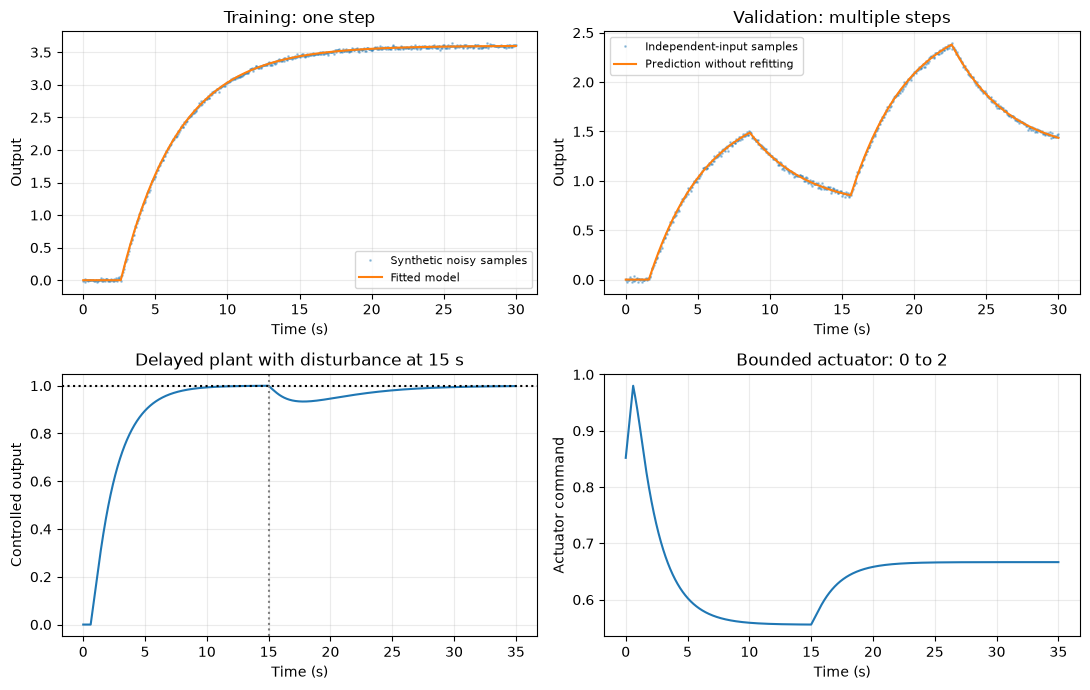

In [3]:
fig,axes=plt.subplots(2,2,figsize=(11,7))
axes[0,0].plot(time,training,'.',ms=2,alpha=.35,label='Synthetic noisy samples'); axes[0,0].plot(time,step_model(time,*estimated),label='Fitted model')
axes[0,0].set(xlabel='Time (s)',ylabel='Output',title='Training: one step'); axes[0,0].legend(fontsize=8)
axes[0,1].plot(time,validation,'.',ms=2,alpha=.35,label='Independent-input samples'); axes[0,1].plot(time,validation_prediction,label='Prediction without refitting')
axes[0,1].set(xlabel='Time (s)',ylabel='Output',title='Validation: multiple steps'); axes[0,1].legend(fontsize=8)
axes[1,0].plot(control_time,output); axes[1,0].axhline(1,color='black',ls=':'); axes[1,0].axvline(15,color='gray',ls=':')
axes[1,0].set(xlabel='Time (s)',ylabel='Controlled output',title='Delayed plant with disturbance at 15 s')
axes[1,1].plot(control_time,effort); axes[1,1].set(xlabel='Time (s)',ylabel='Actuator command',title='Bounded actuator: 0 to 2')
fig.tight_layout()

plt.show()

## Interpret and extend
Training, validation and controller evaluation answer different questions. All three records are synthetic here; experimental claims require independently collected measurements.

Change one parameter at a time, predict the direction of its effect from the equations, and rerun all cells. Explain any discrepancy before accepting a revised conclusion.

## References
- [APMonitor Dynamics and Control](https://apmonitor.com/pdc/)
- [Feedback Systems, open textbook](https://fbsbook.org/)
- [Python Control documentation](https://python-control.readthedocs.io/en/0.10.2/)
- [Worked PDF report](report.pdf)